# 03 – Alignment / registration

**What:** Bring all six filters onto a common pixel grid, so that the same pixel shows the same sky position in every filter.

**Why:** In stage 2 we saw different pixel sizes (0.031″ vs. 0.063″), slightly different image sizes even within one channel, and a rotated image. Without a common grid, overlaying the filters produces colour fringes.

**Microscopy analogy:** channel registration, except that we do *not* need to search for features: each image carries its exact position on the sky in its WCS, similar to stage coordinates plus a calibrated pixel size. `reproject` resamples each image directly onto the target grid. Checking on stars at the end is our test that this is correct.

**Decisions (preliminary, see PLAN.md):**
- Target grid: 0.063″/px (long-wavelength resolution), north up, TAN projection, covering all images
- Method: `reproject_adaptive` (averages sensibly when downsampling, preserves surface brightness)

**Result:** All 6 filters lie on a common grid (3127 × 3121 px, 0.063″/px, north up); stored in `data/ngc3132_nircam_reproj_lw/`. Computing time ≈ 24 s per short-wavelength and ≈ 9 s per long-wavelength image. Star check: mean offset relative to F356W 0.10–0.24 px (6–15 mas), well below one pixel.

In [1]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import warnings
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch
from reproject import reproject_adaptive
from reproject.mosaicking import find_optimal_celestial_wcs
from skimage.feature import peak_local_max

# Explained in notebook 02 – harmless; silenced here to keep the output readable.
warnings.simplefilter("ignore", FITSFixedWarning)

DATA_DIR = Path("..") / "data" / "ngc3132_nircam"
OUT_DIR = Path("..") / "data" / "ngc3132_nircam_reproj_lw"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_RES = 0.063 * u.arcsec   # long-wavelength pixel scale

def band_name(path):
    """F405N instead of 'F444W;F405N': the narrow filter defines the band."""
    h = fits.getheader(path, ext=0)
    return h["PUPIL"] if h["PUPIL"] != "CLEAR" else h["FILTER"]

FILES = {band_name(f): f for f in sorted(DATA_DIR.glob("*_i2d.fits"))}
BANDS = sorted(FILES, key=lambda b: int(b[1:4]))   # sort by wavelength
print(BANDS)

['F090W', 'F187N', 'F212N', 'F356W', 'F405N', 'F470N']


## 1. Determine the target grid

`find_optimal_celestial_wcs` looks at the position of all six images on the sky and builds a WCS that covers them all, with the desired pixel size and north up. Only headers and image sizes are needed, no pixel values.

Because the original images are rotated, the target grid becomes larger than a single image (the corners stay empty/NaN). We crop this later.

In [2]:
inputs = []
for band in BANDS:
    with fits.open(FILES[band], memmap=True) as hdul:
        hdr = hdul["SCI"].header
        inputs.append(((hdr["NAXIS2"], hdr["NAXIS1"]), WCS(hdr)))

# (shape, wcs) tuples are enough for the footprint; if your reproject version
# rejects them, use (np.empty(shape, np.float32), wcs) instead.
wcs_out, shape_out = find_optimal_celestial_wcs(inputs, resolution=TARGET_RES)

scale = (proj_plane_pixel_scales(wcs_out) * u.deg).to(u.arcsec)
print("target shape:", shape_out)
print("target pixel scale:", np.round(scale, 4))
print(f"memory per reprojected band: {np.prod(shape_out) * 4 / 1e6:.0f} MB (float32)")

target shape: (3127, 3121)
target pixel scale: [0.063 0.063] arcsec
memory per reprojected band: 39 MB (float32)


## 2. Test run with a short-wavelength image

One image first (F090W, the largest) to check runtime and result before all six run.

`conserve_flux=False` is correct here: our unit is a *surface brightness* (per solid angle). When four small pixels become one large pixel, the value should be averaged, not summed – like binning with "Average" instead of "Sum".

F090W reprojected in 24.2 s
valid pixels: 57.3 %


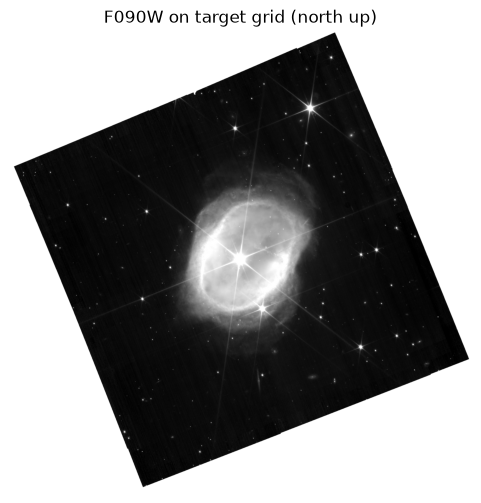

In [3]:
def reproject_band(band):
    with fits.open(FILES[band], memmap=True) as hdul:
        sci = hdul["SCI"].data.astype(np.float32)
        wcs_in = WCS(hdul["SCI"].header)
        bunit = hdul["SCI"].header.get("BUNIT", "")
    array, footprint = reproject_adaptive((sci, wcs_in), wcs_out, shape_out=shape_out,
                                          conserve_flux=False)
    return array.astype(np.float32), footprint.astype(np.float32), bunit

t0 = time.perf_counter()
test, test_fp, _ = reproject_band("F090W")
print(f"F090W reprojected in {time.perf_counter() - t0:.1f} s")
print(f"valid pixels: {100 * np.isfinite(test).mean():.1f} %")

norm = ImageNormalize(test, interval=PercentileInterval(99), stretch=AsinhStretch())
plt.figure(figsize=(6, 6))
plt.imshow(test, origin="lower", cmap="gray", norm=norm)
plt.title("F090W on target grid (north up)")
plt.axis("off");

## 3. Reproject and save all six filters

Each result is saved as its own FITS file (SCI + FOOTPRINT), so that stage 4 can build on it directly and we do not have to repeat this computationally expensive step. The key information (filter, unit, method) goes into the header so that the files remain self-explanatory.

The runtime depends on the image size; the short-wavelength images take considerably longer.

In [4]:
reproj = {}
for band in BANDS:
    out_path = OUT_DIR / f"ngc3132_{band.lower()}_reproj_lw.fits"
    t0 = time.perf_counter()
    if band == "F090W":
        array, footprint, bunit = test, test_fp, "MJy/sr"
    else:
        array, footprint, bunit = reproject_band(band)
    reproj[band] = array

    hdr = wcs_out.to_header()
    hdr["BAND"] = (band, "filter defining the passband")
    hdr["BUNIT"] = bunit
    hdr["SRCFILE"] = FILES[band].name
    hdr["REPROJ"] = ("reproject_adaptive", "conserve_flux=False")
    fits.HDUList([
        fits.PrimaryHDU(data=array, header=hdr),
        fits.ImageHDU(data=footprint, header=wcs_out.to_header(), name="FOOTPRINT"),
    ]).writeto(out_path, overwrite=True)
    print(f"{band:<6} {time.perf_counter() - t0:6.1f} s  -> {out_path.name}")

F090W     0.1 s  -> ngc3132_f090w_reproj_lw.fits
F187N    23.9 s  -> ngc3132_f187n_reproj_lw.fits
F212N    23.9 s  -> ngc3132_f212n_reproj_lw.fits
F356W     8.8 s  -> ngc3132_f356w_reproj_lw.fits
F405N     8.9 s  -> ngc3132_f405n_reproj_lw.fits
F470N     8.9 s  -> ngc3132_f470n_reproj_lw.fits


## 4. Overview: all filters on the same grid

Same display for all (asinh, 0.5–99.5 %), only as a visual check. All six should now show exactly the same field in the same orientation.

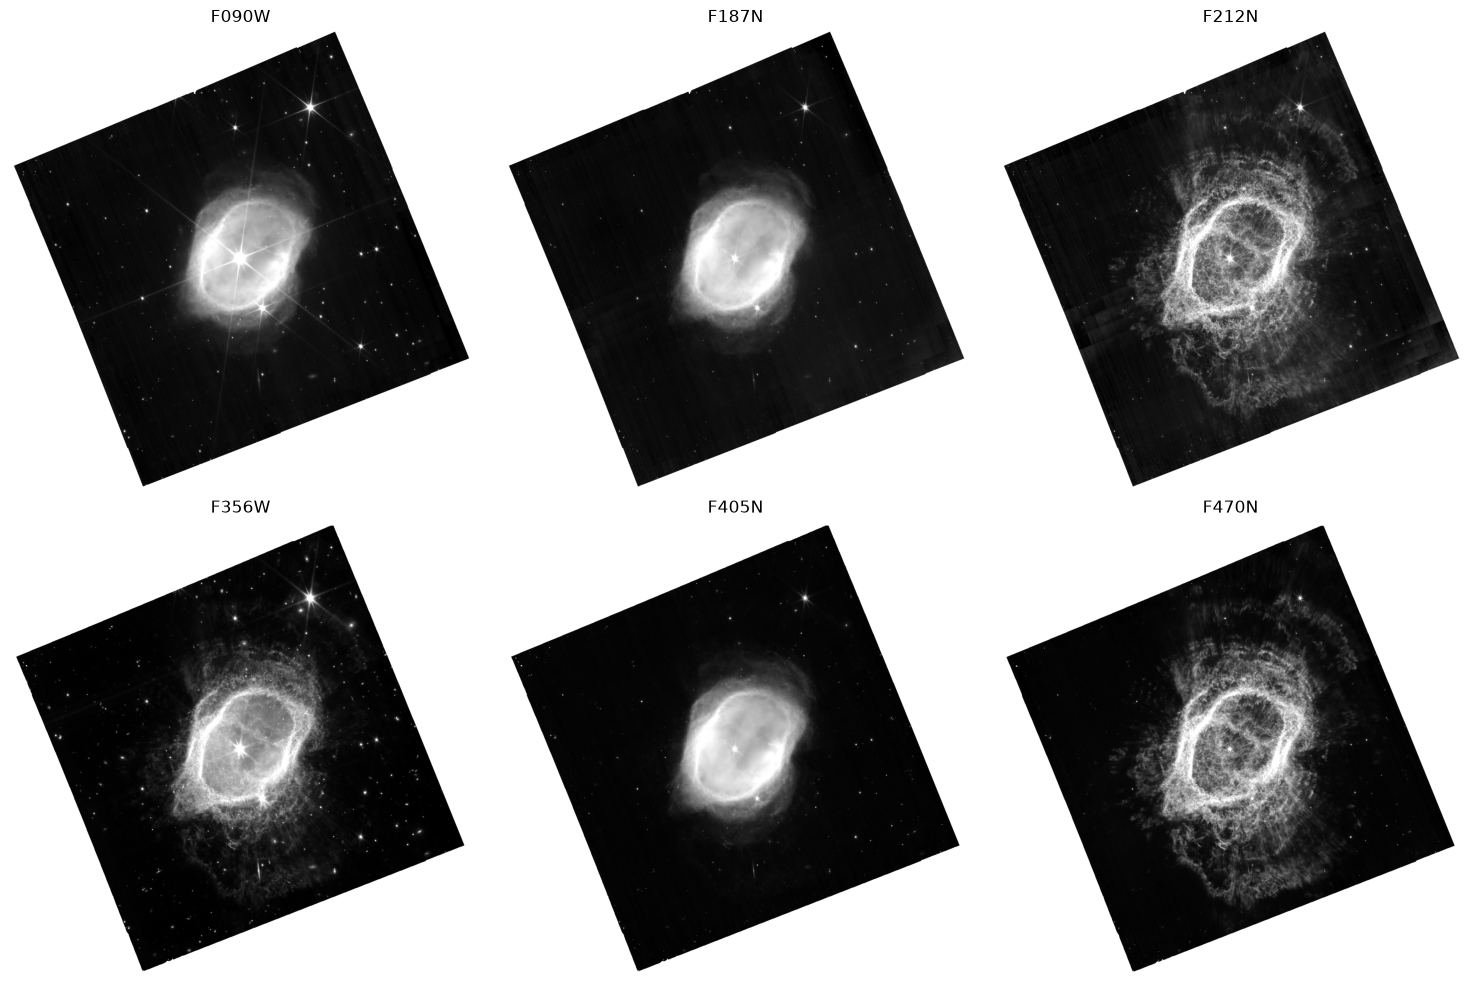

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, band in zip(axes.flat, BANDS):
    img = reproj[band]
    ax.imshow(img, origin="lower", cmap="gray",
              norm=ImageNormalize(img, interval=PercentileInterval(99), stretch=AsinhStretch()))
    ax.set_title(band)
    ax.axis("off")
plt.tight_layout()

## 5. Check 1: compare star positions

Stars are point sources and therefore ideal fiducials, like fluorescent beads in channel registration. We look for bright stars in F356W and compute the intensity-weighted centre (centroid) in a small box in each filter.

Expectation: deviations well below 1 pixel (1 px = 63 mas). Single outliers are possible, e.g. when a star's core is saturated (then the core is often NaN in the image) or nebula lies in the box; boxes containing NaN are skipped.

In [6]:
ref = np.nan_to_num(reproj["F356W"], nan=0.0)
peaks = peak_local_max(ref, min_distance=40, num_peaks=12, exclude_border=60)

def centroid(img, y, x, half=5):
    box = img[y - half:y + half + 1, x - half:x + half + 1]
    if box.shape != (2 * half + 1,) * 2 or not np.all(np.isfinite(box)):
        return None
    edge = np.concatenate([box[0], box[-1], box[1:-1, 0], box[1:-1, -1]])
    w = np.clip(box - np.median(edge), 0, None)
    if w.sum() <= 0:
        return None
    yy, xx = np.mgrid[-half:half + 1, -half:half + 1]
    return y + (w * yy).sum() / w.sum(), x + (w * xx).sum() / w.sum()

print(f"{'star':<5}{'y':>6}{'x':>6} | " + "".join(f"{b:>9}" for b in BANDS))
offsets = {b: [] for b in BANDS}
for i, (y, x) in enumerate(peaks):
    c_ref = centroid(reproj["F356W"], y, x)
    if c_ref is None:
        continue
    cells = []
    for b in BANDS:
        c = centroid(reproj[b], y, x)
        if c is None:
            cells.append(f"{'–':>9}")
            continue
        d = np.hypot(c[0] - c_ref[0], c[1] - c_ref[1])
        offsets[b].append(d)
        cells.append(f"{d:9.2f}")
    print(f"{i:<5}{y:6d}{x:6d} | " + "".join(cells))

print("\nmedian offset vs. F356W [px]  (1 px = 63 mas):")
for b in BANDS:
    if offsets[b]:
        print(f"  {b:<6} {np.median(offsets[b]):.2f} px  ({len(offsets[b])} stars)")

star      y     x |     F090W    F187N    F212N    F356W    F405N    F470N
0       987  2373 |         –     0.14     0.15     0.00     0.24     0.24
1      2467  1523 |      0.25     0.06     0.10     0.00     0.23     0.24
2      1645  2480 |      0.24     0.15     0.07     0.00     0.23     0.18
3      1313   896 |      0.08     0.16     0.11     0.00     0.24     0.21
4      1905   925 |      0.03     0.18     0.11     0.00     0.20     0.20
6      1613  2375 |      0.21     0.14     0.06     0.00     0.25     0.20
9      1063  2617 |      0.23     0.17     0.10     0.00     0.24     0.18
10     2947  2174 |      0.14     0.10     0.09     0.00     0.09     0.10
11     1949   390 |      0.05     0.23     0.24     0.00     0.30     0.44

median offset vs. F356W [px]  (1 px = 63 mas):
  F090W  0.18 px  (8 stars)
  F187N  0.15 px  (9 stars)
  F212N  0.10 px  (9 stars)
  F356W  0.00 px  (9 stars)
  F405N  0.24 px  (9 stars)
  F470N  0.20 px  (9 stars)


## 6. Check 2: colour overlay on a star

Like a colocalisation overlay: F090W in magenta, F356W in green. If both coincide, the star turns white; an offset shows up as a magenta/green fringe. Shown is a cutout around the brightest well-measurable star from check 1.

(The stars look smaller in F090W than in F356W because the diffraction limit grows with wavelength. This is not a registration error.)

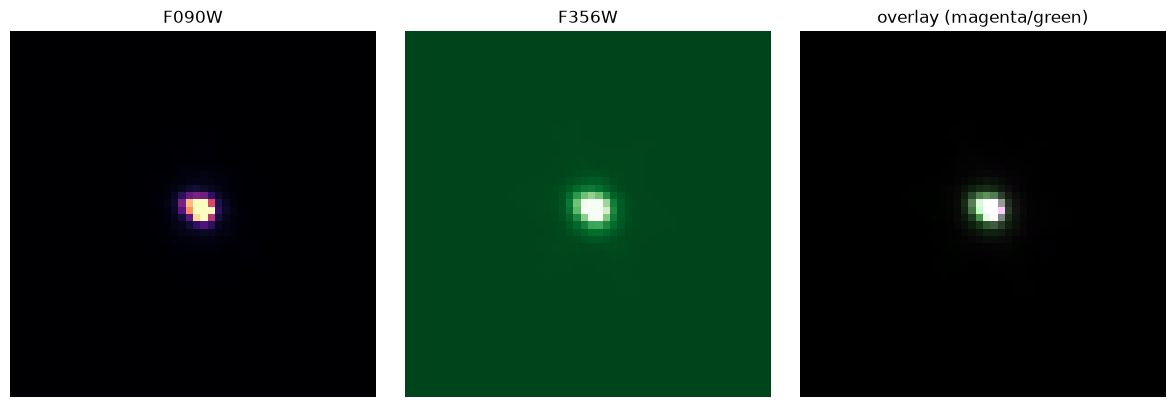

In [7]:
def to01(img, lo=1, hi=99.8):
    v = img[np.isfinite(img)]
    a, b = np.percentile(v, [lo, hi])
    return np.clip(np.nan_to_num((img - a) / (b - a)), 0, 1)

# first peak for which all bands gave a centroid
y, x = next((p for p in peaks if all(centroid(reproj[b], *p) is not None for b in BANDS)), peaks[0])
half = 25
crop = np.s_[y - half:y + half, x - half:x + half]
m, g = to01(reproj["F090W"][crop]), to01(reproj["F356W"][crop])
rgb = np.dstack([m, g, m])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(m, origin="lower", cmap="magma"); axes[0].set_title("F090W")
axes[1].imshow(g, origin="lower", cmap="Greens_r"); axes[1].set_title("F356W")
axes[2].imshow(rgb, origin="lower"); axes[2].set_title("overlay (magenta/green)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

## Conclusion

- **Target grid:** 3127 × 3121 px at 0.063″/px. Larger than a single image (≈ 2350 px) because the originals are rotated by ≈ 22° relative to north: bounding box ≈ (cos 22° + sin 22°) ≈ 1.30× larger. Accordingly only ≈ 57 % of the pixels are valid (expected ≈ 1/1.30² ≈ 59 %); the rest are empty corners.
- **Method:** `reproject_adaptive` with `conserve_flux=False` (averages when downsampling the short-wavelength images, preserves surface brightness). Fast enough: ≈ 24 s (SW) or ≈ 9 s (LW) per filter, ≈ 39 MB RAM per filter.
- **Check on 9 stars:** mean offset relative to F356W: F090W 0.18 px, F187N 0.15, F212N 0.10, F405N 0.24, F470N 0.20 (1 px = 63 mas). For comparison: star width at 4 µm ≈ 2 px → offset ≈ 10 % of it, invisible in the colour image. No fine alignment needed.
- **Oddities:** star 11 (image edge, x = 390) is the outlier (up to 0.44 px), consistent with the lower exposure at the edge. F405N/F470N are slightly higher than the SW filters although they use the same detector as F356W; cause unclear (pupil filter, or centroid measurement disturbed by nebula/fainter stars). Irrelevant for colour images.
- **Overlay (step 6):** core white (coincident), surrounded by an even green fringe. The fringe is not an offset but the wider star image at 3.56 µm compared with 0.9 µm (diffraction limit ∝ wavelength), like differently sized PSFs of two fluorescence channels. A registration error would be one-sided (magenta on one side, green on the other).
- **Overview (step 4):** F187N/F405N show a smooth inner bubble, F212N/F470N filamentary structures further out → the nebula is layered (probably ionised vs. molecular hydrogen), important for stage 5. F212N shows background artefacts (vertical stripes, rectangular brightness steps), important for stage 4.
- **Decision:** reference grid (0.063″, north up) and method (`reproject_adaptive`) confirmed.

**Next step:** stage 4 – subtract the background and stretch the brightness.